### Evaluation

Notebook to run evaulation on test data

- use daily provided data (evaluation period of competition)

Data: "../data/evaluation/[met_nowcast_daily, met_forecast_daily, wind_power]"


In [ ]:
import os
import sys

sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from jax import random
from numpyro.infer import Predictive
import arviz as az

from validate_example import validate_forecast
from data_processing.load import (
    load_evaluation_data,
    load_weather_forecast_parquet,
    load_and_preprocess_forecast_data,
    rename_met_forecast_columns,
    sin_cos_transform,
    load_weather_nowcast,
)
from data_processing.utils import (
    load_scaler_params,
    load_checkpoint,
    load_torch_model,
    QuantileDistribution,
)
from models.model import model_mw_gamma, model_cf_logitnormal, model_cf_beta
import torch
import re

In [2]:
# TODO
# DONE load evaluation input
# fix column names
# DONE calculate capacity factor
# DONE load model from checkpoint
# DONE (select bidding zone)
# DONE evaluate model for (all) bidding zone
# multiply with available capacity to get absolute generated power
# DONE save median, q025 and q975 in a CSV
# DONE verify format with verify_example.py
# check how good forecast was afterwards (in competition one day later)

In [38]:
forecast = load_weather_forecast_parquet("../data/met_forecast.parquet")
nowcast = load_weather_nowcast("../data/met_nowcast.parquet")

In [39]:
nowcast

,air_temperature_2m,air_pressure_at_sea_level,relative_humidity_2m,precipitation_amount,wind_speed_10m,wind_direction_10m,windpark
time,,,,,,,
2020-01-01 01:00:00+01:00,276.363831,100703.859375,0.966131,3.147963,13.445930,250.681976,Bessakerfjellet
2020-01-01 02:00:00+01:00,276.951080,100595.609375,0.972677,3.636308,13.807796,251.660736,Bessakerfjellet
2020-01-01 03:00:00+01:00,277.113007,100526.656250,0.964682,1.921109,15.788631,250.626617,Bessakerfjellet
2020-01-01 04:00:00+01:00,277.259033,100408.359375,0.966498,1.919362,16.493980,254.728180,Bessakerfjellet
2020-01-01 05:00:00+01:00,277.229248,100421.062500,0.964835,1.275917,16.933884,253.571869,Bessakerfjellet
...,...,...,...,...,...,...,...
2025-03-31 21:00:00+02:00,271.956329,101966.796875,0.962775,1.563930,8.735393,196.803040,Øyfjell2
2025-03-31 22:00:00+02:00,271.778442,101946.859375,0.995688,0.375011,11.672383,206.363098,Øyfjell2
2025-03-31 23:00:00+02:00,271.601746,101986.929688,0.993568,0.034405,10.683748,209.511871,Øyfjell2


In [ ]:
feature_cols = [
    "air_temperature_2m",
    "air_pressure_at_sea_level",
    "relative_humidity_2m",
    "wind_speed_10m",
]

In [12]:
weather_forecast = load_weather_forecast_parquet("../data/met_forecast.parquet")
weather_forecast = rename_met_forecast_columns(weather_forecast)

Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79


In [24]:
weather_forecast.columns

Index(['windpark', 'time_ref', 'time', 'lead_time_hours',
       'wind_speed_10m_member_0', 'wind_speed_10m_member_1',
       'wind_speed_10m_member_2', 'wind_speed_10m_member_3',
       'wind_speed_10m_member_4', 'wind_speed_10m_member_5',
       'wind_speed_10m_member_6', 'wind_speed_10m_member_7',
       'wind_speed_10m_member_8', 'wind_speed_10m_member_9',
       'wind_speed_10m_member_10', 'wind_speed_10m_member_11',
       'wind_speed_10m_member_12', 'wind_speed_10m_member_13',
       'wind_speed_10m_member_14', 'wind_direction_10m_member_0',
       'wind_direction_10m_member_1', 'wind_direction_10m_member_2',
       'wind_direction_10m_member_3', 'wind_direction_10m_member_4',
       'wind_direction_10m_member_5', 'wind_direction_10m_member_6',
       'wind_direction_10m_member_7', 'wind_direction_10m_member_8',
       'wind_direction_10m_member_9', 'wind_direction_10m_member_10',
       'wind_direction_10m_member_11', 'wind_direction_10m_member_12',
       'wind_direction_10m_m

In [ ]:
feature_member_cols = {
    feat: [f"{feat}_member_{i}" for i in range(15)]  # 15 members
    for feat in feature_cols
}

# Dictionary to store variance series per feature
var_by_feature = {}

for feat, cols in feature_member_cols.items():
    # Compute variance across members for each lead time
    # 1. variance across members, within each windpark and lead time
    df_var = (
        weather_forecast.groupby(["windpark", "lead_time_hours"])[cols]
        .var()  # variance of the 15 member columns
        .mean(axis=1)  # mean across member columns (→ single variance number)
        .reset_index(name="var")  # tidy output
    )

    # 2. average across windparks for each lead time
    avg_var = df_var.groupby("lead_time_hours")["var"].mean()

    var_by_feature[feat] = avg_var

In [93]:
var_overall = pd.DataFrame(var_by_feature)

In [95]:
var_overall.mean(axis=1)

lead_time_hours
0     397804.510842
1     396797.720415
2     395460.603098
3     393857.297232
4     392738.588242
          ...      
60    394726.854172
61    395010.884728
62    435803.697062
63    436172.067038
64    436867.813919
Length: 65, dtype: float64

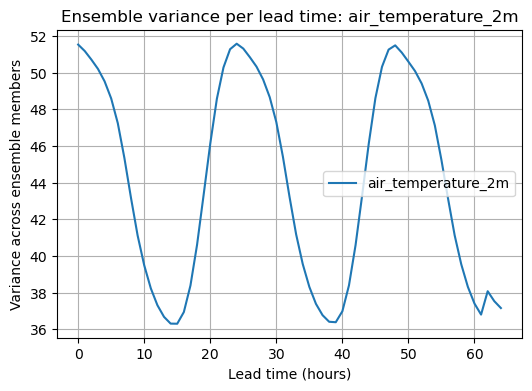

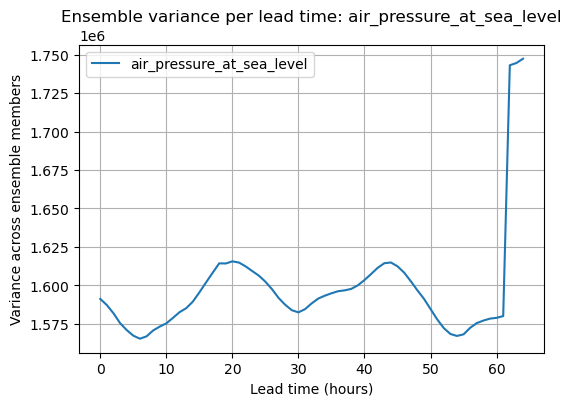

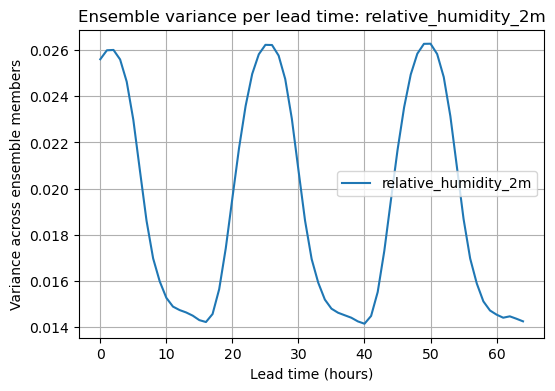

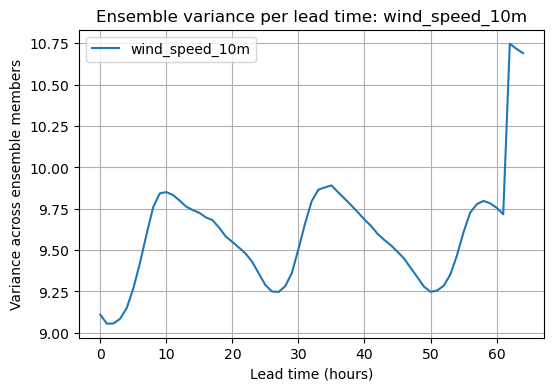

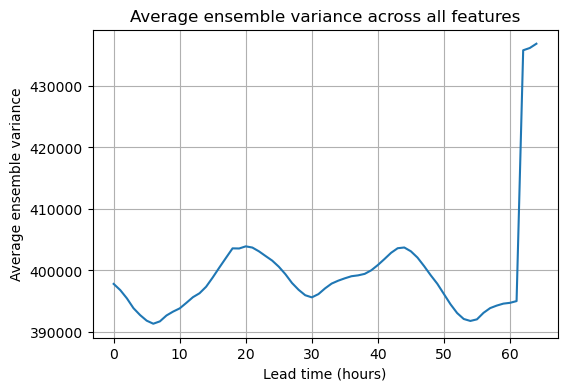

In [99]:
for feat, series in var_by_feature.items():
    plt.figure(figsize=(6, 4))
    plt.plot(series.index, series.values, label=feat)
    plt.xlabel("Lead time (hours)")
    plt.ylabel("Variance across ensemble members")
    plt.title(f"Ensemble variance per lead time: {feat}")
    plt.legend()
    plt.grid(True)
    plt.show()

plt.figure(figsize=(6, 4))
plt.plot(var_overall.mean(axis=1))
plt.xlabel("Lead time (hours)")
plt.ylabel("Average ensemble variance")
plt.title("Average ensemble variance across all features")
plt.grid(True)
plt.show()

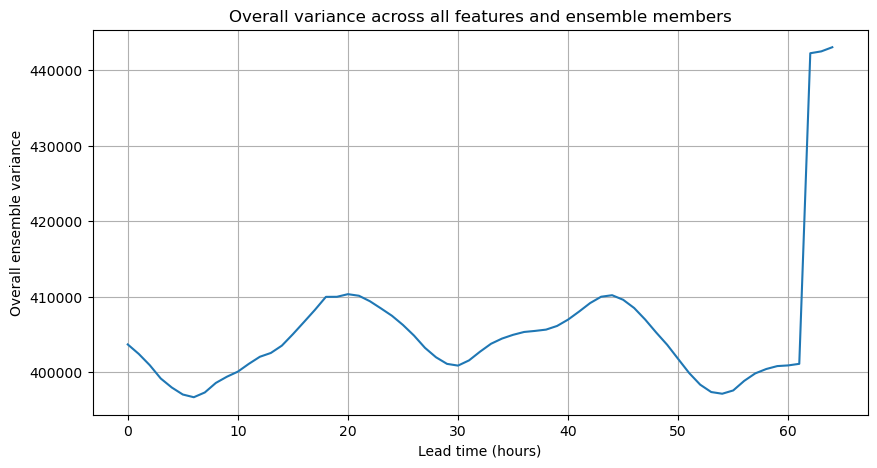

In [100]:
all_member_cols = [f"{feat}_member_{i}" for feat in feature_cols for i in range(15)]
overall_variance = (
    weather_forecast.groupby("lead_time_hours")[all_member_cols]
    .var()  # variance across all member columns
    .mean(axis=1)  # reduce 90 variances to ONE value per lead time
)
plt.figure(figsize=(10, 5))
plt.plot(overall_variance.index, overall_variance.values)

plt.xlabel("Lead time (hours)")
plt.ylabel("Overall ensemble variance")
plt.title("Overall variance across all features and ensemble members")
plt.grid(True)
plt.show()

In [60]:
forecast

,sid,time_ref,time,lt,ws10m_00,ws10m_01,ws10m_02,ws10m_03,ws10m_04,ws10m_05,...,g10m_05,g10m_06,g10m_07,g10m_08,g10m_09,g10m_10,g10m_11,g10m_12,g10m_13,g10m_14
0,Engerfjellet,2020-02-15 13:00:00+01:00,2020-02-15 13:00:00+01:00,0,2.096957,2.110652,2.304629,1.942044,1.447011,2.288181,...,6.918935,8.110546,5.988888,6.934274,5.235212,5.507061,7.193576,6.753938,4.841811,4.875890
1,Engerfjellet,2020-02-15 13:00:00+01:00,2020-02-15 14:00:00+01:00,1,3.449402,3.436193,3.205872,3.450461,3.143307,4.278822,...,9.914339,9.184751,6.999992,7.892150,7.214608,8.252510,9.535547,8.717684,8.152432,6.240438
2,Engerfjellet,2020-02-15 13:00:00+01:00,2020-02-15 15:00:00+01:00,2,3.348926,2.903557,2.779971,3.733802,3.148597,2.912592,...,10.031385,8.624619,7.984353,8.264300,7.205638,9.052546,9.531441,8.367238,7.840395,7.153080
3,Engerfjellet,2020-02-15 13:00:00+01:00,2020-02-15 16:00:00+01:00,3,3.095971,2.560161,2.448126,2.267286,3.050008,3.310141,...,8.185250,8.821701,7.481009,8.172009,6.255360,7.345034,8.303812,6.735660,7.600200,7.189164
4,Engerfjellet,2020-02-15 13:00:00+01:00,2020-02-15 17:00:00+01:00,4,2.821545,2.965743,3.235484,3.212730,3.064931,2.420390,...,7.551644,9.709259,8.365305,8.703517,6.151643,10.116440,7.346225,9.079601,9.048587,6.937930
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6874207,Hamnefjell,2025-03-15 10:00:00+01:00,2025-03-18 02:00:00+01:00,64,6.872266,7.164222,6.316023,5.589070,6.980499,4.612734,...,7.563049,8.551785,9.509587,9.794330,8.066090,8.411860,10.138005,2.795730,9.581801,7.873007
6874208,Hamnefjell,2025-03-16 10:00:00+01:00,2025-03-19 02:00:00+01:00,64,16.470940,16.099072,7.887674,14.270714,4.360876,10.369994,...,14.324461,30.275700,8.210348,18.635717,10.935499,18.720608,26.935497,6.617165,21.847015,31.888178
6874209,Hamnefjell,2025-03-22 10:00:00+01:00,2025-03-25 02:00:00+01:00,64,10.446624,9.178246,12.801767,9.458190,9.951641,8.660180,...,13.481665,18.230787,13.330455,16.758130,10.482368,10.948782,14.067688,15.863382,13.946945,12.476421
6874210,Hamnefjell,2025-03-23 10:00:00+01:00,2025-03-26 02:00:00+01:00,64,18.683716,16.797531,16.638610,16.367867,17.087458,13.853215,...,19.608253,25.046673,13.443735,19.931894,24.276434,25.254436,17.580925,24.548616,27.329407,19.575188


In [1]:
import os
import sys

sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from jax import random
from numpyro.infer import Predictive
import arviz as az

from validate_example import validate_forecast
from data_processing.load import (
    load_evaluation_data,
    load_weather_forecast_parquet,
    load_and_preprocess_forecast_data,
    rename_met_forecast_columns,
    sin_cos_transform,
)
from data_processing.utils import (
    load_scaler_params,
    load_checkpoint,
    load_torch_model,
    QuantileDistribution,
)
from models.model import model_mw_gamma, model_cf_logitnormal, model_cf_beta
import torch
import re

In [24]:
bid_zone = "ELSPOT NO1"
dataset = "forecast"
evaluation_dates = [
    "2025-09-22",
    "2025-09-23",
    "2025-09-24",
    "2025-09-25",
    "2025-09-26",
    "2025-09-29",
    "2025-09-30",
    "2025-10-01",
    "2025-10-02",
    "2025-10-03",
]

In [25]:
bid_zones = ["ELSPOT NO1", "ELSPOT NO2", "ELSPOT NO3", "ELSPOT NO4"]
bid_zones = [bz.replace(" ", "_") for bz in bid_zones]

### Load params and evaluation data


In [26]:
# Load scaler params (same for all models in this bid zone)
scaler_data = load_scaler_params(
    bid_zone=bid_zone, dataset=dataset, dir_path="../checkpoints"
)

Loaded scaler parameters for ELSPOT NO1 and forecast
  Saved at: 2025-12-10 12:23:23
  Split time: 2025-01-01 00:00:00+01:00


In [27]:
scaler_data["scaler_params"].keys()

dict_keys(['mean', 'scale', 'columns'])

In [28]:
# Load evaluation data for multiple dates (using the evaluation_dates list)
eval_data = load_evaluation_data(
    dates=evaluation_dates,
    scaler_params=scaler_data["scaler_params"],
    site_scaler_params=scaler_data["site_scaler_params"],
    bid_zone=bid_zone,
    dataset=dataset,
    ensemble_member=0,
    variance_feature=True,
)

Loading evaluation data for 10 dates in zone ELSPOT NO1...
Loading evaluation data for 2025-09-22 in zone ELSPOT NO1
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79
Selected ensemble member 0
  Features: ['wind_speed_10m', 'wind_direction_10m', 'air_temperature_2m', 'relative_humidity_2m', 'air_pressure_at_sea_level', 'wind_direction_10m_x', 'wind_direction_10m_y']
Filtered to target day: 2025-09-24
Loading evaluation data for 2025-09-23 in zone ELSPOT NO1
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79
Selected ensemble member 0
  Features: ['wind_speed_10m', 'wind_direction_10m', 'air_temperature_2m', 'relative_humidity_2m', 'air_pressure_at_sea_level', 'wind_direction_10m_x', 'wind_direction_10m_y']
Filtered to target day: 2025-09-25
Loading evaluation data for 2

/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:63: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


Selected ensemble member 0
  Features: ['wind_speed_10m', 'wind_direction_10m', 'air_temperature_2m', 'relative_humidity_2m', 'air_pressure_at_sea_level', 'wind_direction_10m_x', 'wind_direction_10m_y']
Filtered to target day: 2025-10-04
Loading evaluation data for 2025-10-03 in zone ELSPOT NO1
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79
Selected ensemble member 0
  Features: ['wind_speed_10m', 'wind_direction_10m', 'air_temperature_2m', 'relative_humidity_2m', 'air_pressure_at_sea_level', 'wind_direction_10m_x', 'wind_direction_10m_y']
Filtered to target day: 2025-10-05


QUEUEING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?it…

PROCESSING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?…

COLLECTING RESULTS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?,…

Evaluation data shape: X=(240, 6, 11), Y_gen=(240,)


In [ ]:
# Load trained model checkpoint, bidding zone specific!
checkpoint = load_checkpoint(file_name="model_mw_gamma_2025-11-13_10-56-50_gen")

Loading specified checkpoint: ../checkpoints/WindPowerQuantile_2025-12-09_13-24-38_forecast_gen_ELSPOT_NO1.pt.pkl


FileNotFoundError: [Errno 2] No such file or directory: '../checkpoints/WindPowerQuantile_2025-12-09_13-24-38_forecast_gen_ELSPOT_NO1.pt.pkl'

### Run inference


In [10]:
_, rng_key_predict = random.split(checkpoint["rng_key"])

predictive = Predictive(model_mw_gamma, checkpoint["samples"])(
    rng_key_predict, eval_data["X_eval"]
)

preds = predictive["Y"]
mu = predictive["mu"]
alpha = predictive["alpha"]

median = np.percentile(preds, 50, axis=0)
q025 = np.percentile(preds, 2.5, axis=0)
q975 = np.percentile(preds, 97.5, axis=0)
hdi = az.hdi(np.expand_dims(preds, axis=0), hdi_prob=0.95)

### Save predictions as CSV


In [31]:
# forecast = pd.DataFrame(
#     index=eval_data["index"],
#     columns=bid_zones,
#     data=0,
# )
# forecast_extended = [
#     pd.DataFrame(
#         index=eval_data["index"],
#         columns=["median", "hdi_lower", "hdi_upper"],
#         data=0,
#     )
#     for _ in range(len(bid_zones))
# ]

### Evaluate BNN


In [15]:
def evaluate_BNN(file_name):

    forecast = pd.DataFrame(
        index=eval_data["index"],
        columns=bid_zones,
        data=0,
    )
    forecast_extended = [
        pd.DataFrame(
            index=eval_data["index"],
            columns=["median", "hdi_lower", "hdi_upper"],
            data=0,
        )
        for _ in range(len(bid_zones))
    ]
    model_mapping = {
        "model_cf_beta": model_cf_beta,
        "model_mw_gamma": model_mw_gamma,
        "model_cf_logitnormal": model_cf_logitnormal,
    }

    for i, bz in enumerate(bid_zones):

        # Load bid zone specific trained model checkpoint
        # TODO make it bidzone specific
        model_name = re.match(r"^(.*?)_\d{4}-\d{2}-\d{2}", file_name).group(1)
        print(model_name)
        checkpoint = load_checkpoint(
            file_name=file_name
        )  # TODO make it bid zone specific

        # Run inference
        _, rng_key_predict = random.split(checkpoint["rng_key"])

        predictive = Predictive(model_mapping[model_name], checkpoint["samples"])(
            rng_key_predict, eval_data["X_eval"]
        )

        preds = predictive["Y"]
        if "cf" in checkpoint["model_name"]:
            preds *= eval_data["Y_eval_aval"]

        median = np.percentile(preds, 50, axis=0)
        hdis = az.hdi(np.expand_dims(preds, axis=0), hdi_prob=0.95)
        hdi_lower, hdi_upper = hdis[:, 0], hdis[:, 1]

        forecast[bz] = median
        forecast_extended[i][["median", "hdi_lower", "hdi_upper"]] = np.column_stack(
            [median, hdi_lower, hdi_upper]
        )

        break  # TODO no checkpoints for other bid zones so far

    return forecast, forecast_extended

In [31]:
# file_name = "model_mw_gamma_2025-11-21_10-30-46_gen_ELSPOT_NO1"
# file_name="model_cf_beta_2025-12-01_10-03-45_cf_ELSPOT_NO1"
# file_name= "model_mw_gamma_2025-11-13_10-56-50_gen"
# file_name="model_mw_gamma_2025-12-02_11-42-42_fore_ELSPOT_NO1"
# file_name="model_cf_beta_2025-12-02_11-42-42_fore_ELSPOT_NO1"
# file_name ="model_mw_gamma_2025-12-02_11-42-42_fore_ELSPOT_NO1" #"model_cf_beta_2025-12-02_11-42-42_fore_ELSPOT_NO1"  # "model_mw_gamma_2025-11-13_10-56-50_gen"


# file_name="model_mw_gamma_2025-12-10_11-15-46_nowcast_ELSPOT_NO1"
# file_name = "model_mw_gamma_2025-12-10_11-32-23_forecast_ELSPOT_NO1"
file_name = "model_cf_beta_2025-12-10_11-50-14_forecast_ELSPOT_NO1"
forecast, forecast_extended = evaluate_BNN(file_name)

model_cf_beta
Loading specified checkpoint: ../checkpoints/model_cf_beta_2025-12-10_11-50-14_forecast_ELSPOT_NO1.pkl


### Evaluate deterministic NN


In [ ]:
def evaluate_QR(file_name):
    forecast = pd.DataFrame(
        index=eval_data["index"],
        columns=bid_zones,
        data=0,
    )
    forecast_extended = [
        pd.DataFrame(
            index=eval_data["index"],
            columns=["median", "hdi_lower", "hdi_upper"],
            data=0,
        )
        for _ in range(len(bid_zones))
    ]

    for i, bz in enumerate(bid_zones):

        loaded_model, checkpoint_data = load_torch_model(file_name=file_name)

        loaded_model.eval()
        with torch.no_grad():

            if "Quantile" in checkpoint_data["model_name"]:
                y_sum_pred = loaded_model(torch.tensor(eval_data["X_eval"]))

                if "cf" in file_name:
                    y_sum_pred *= eval_data["Y_eval_aval"][:, None]
                Y_pred = y_sum_pred.numpy()

                taus = np.linspace(0, 1, 51)
                dist = QuantileDistribution(taus, np.mean(Y_pred, axis=0))
                hdis = np.array(
                    [
                        QuantileDistribution(taus, Y_pred[i]).hdi(
                            cred_mass=0.95, n_samples=5000
                        )
                        for i in range(eval_data["Y_eval_gen"].shape[0])
                    ]
                )

                medians = np.array(
                    [
                        QuantileDistribution(taus, Y_pred[i]).icdf(0.5)
                        for i in range(eval_data["Y_eval_gen"].shape[0])
                    ]
                )

                forecast_extended[i][["median", "hdi_lower", "hdi_upper"]] = (
                    np.column_stack([medians, hdis[:, 0], hdis[:, 1]])
                )

            else:  # TODO catch more models here
                _, y_sum_pred = loaded_model(torch.tensor(eval_data["X_eval"]))
                y_sum_pred = y_sum_pred.numpy() * eval_data["Y_eval_aval"]  # CF
                medians = y_sum_pred  # np.percentile(y_sum_pred, 50, axis=0)
                forecast_extended[i]["median"] = medians

        forecast[bz] = medians

        break  # TODO no checkpoints for other bid zones so far

    return forecast, forecast_extended

In [ ]:
# file_name = "WindPowerQuantile_2025-12-10_10-57-24_nowcast_gen_ELSPOT_NO1"
# file_name="WindPowerQuantile_2025-12-10_11-11-46_nowcast_cf_ELSPOT_NO1"
# file_name= "WindPowerQuantile_2025-12-10_12-29-26_foreast_gen_ELSPOT_NO1"
file_name = "WindPowerQuantile_2025-12-10_12-41-56_foreast_cf_ELSPOT_NO1"
forecast, forecast_extended = evaluate_QR(file_name)

Loaded model: WindPowerQuantile_2025-12-10_12-41-56_foreast_cf_ELSPOT_NO1.pt
  Bid zone: ELSPOT NO1
  Model class: WindPowerQuantile


/var/folders/x4/fy_84p8n71gbcmjs7c03bd640000gn/T/ipykernel_18883/2651320551.py:27: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  y_sum_pred *= eval_data["Y_eval_aval"][:, None]


In [ ]:
# # Save predictions to CSV
# data_folder = f"../data/evaluation/eval_period"
# file_path = f"{data_folder}/forecast.csv"
# if not os.path.exists(data_folder):
#     os.makedirs(data_folder)
# forecast.to_csv(file_path)

In [ ]:
# # Validate format
# df = validate_forecast(file_path)

### Metrics


In [41]:
i = 0  # [0,1,2,3], choose which bid zone should be plotted
bid_zone = f"ELSPOT_NO{i+1}"
rmse = np.sqrt(np.mean((forecast[bid_zone] - eval_data["Y_eval_gen"]) ** 2))

print("Test RMSE (gen prediction):", rmse)
inside = (eval_data["Y_eval_gen"] >= forecast_extended[i]["hdi_lower"]) & (
    eval_data["Y_eval_gen"] <= forecast_extended[i]["hdi_upper"]
)
coverage_90 = inside.mean()
print(f"\nEmpirical coverage (0.025–0.975): {coverage_90:.3f}")

below_median = (eval_data["Y_eval_gen"] <= forecast_extended[i]["median"]).mean()
print(f"Below median (should be ~0.5): {below_median:.3f}")

Test RMSE (gen prediction): 91.89512112352

Empirical coverage (0.025–0.975): 0.613
Below median (should be ~0.5): 0.246


### Plot prediction


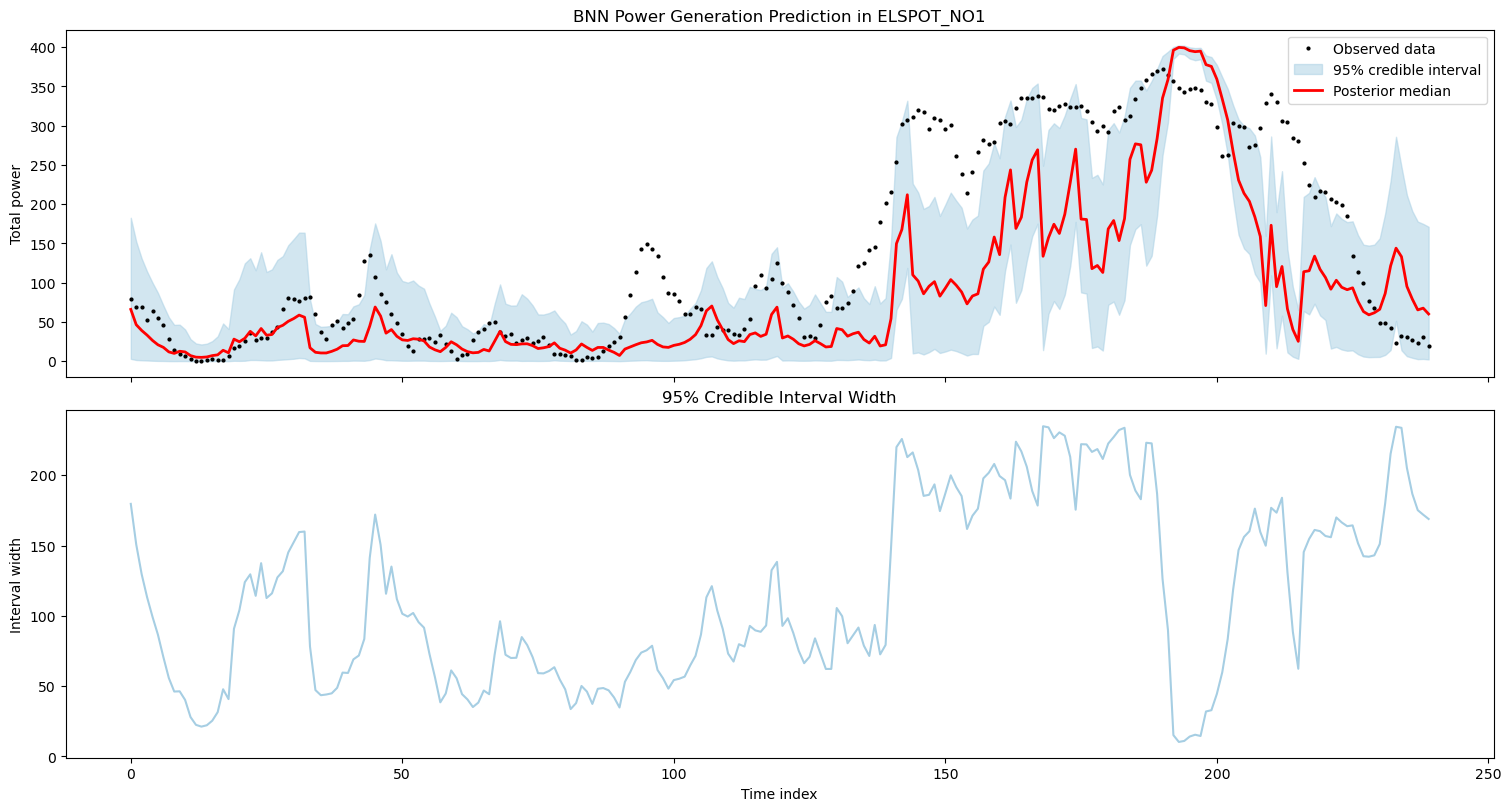

In [42]:
fig, axes = plt.subplots(nrows=2, figsize=(15, 8), sharex=True, constrained_layout=True)

ax = axes[0]
ax.plot(
    eval_data["Y_eval_gen"],
    ".",
    color="black",
    label="Observed data",
    markersize=4,
)

ax.fill_between(
    np.arange(24 * len(evaluation_dates)),
    forecast_extended[i]["hdi_lower"].values,
    forecast_extended[i]["hdi_upper"].values,
    color="#A6CEE3",
    alpha=0.5,
    label="95% credible interval",
)

ax.plot(
    forecast_extended[i]["median"].values, color="red", label="Posterior median", lw=2
)

ax.set(
    ylabel="Total power",
    title=f"BNN Power Generation Prediction in {bid_zone}",
)
ax.legend()


# Compute interval width
width = (
    forecast_extended[i]["hdi_upper"].values - forecast_extended[i]["hdi_lower"].values
)
ax2 = axes[1]
ax2.plot(width, color="#A6CEE3")
ax2.set(
    xlabel="Time index",
    ylabel="Interval width",
    title="95% Credible Interval Width",
)

plt.show()

In [ ]:
# # First, load nowcast data (or load existing scaler params)
# nowcast_data = load_and_preprocess_data(bid_zone="ELSPOT NO1")

In [53]:
import importlib
import data_processing.load as load_module

importlib.reload(load_module)
from data_processing.load import (
    load_evaluation_data,
    load_weather_forecast_parquet,
    load_and_preprocess_forecast_data,
)

In [54]:
# # Now load forecast data using the SAME scaler parameters

forecast_data = load_and_preprocess_forecast_data(
    scaler_params=None,
    site_scaler_params=None,
    bid_zone="ELSPOT NO1",
    ensemble_member=0,  # Use member 0
    data_path="../data",
)

Loading forecast data for ELSPOT NO1, ensemble member 0...
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79
Selected ensemble member 0
  Features: ['wind_speed_10m', 'wind_direction_10m', 'air_temperature_2m', 'relative_humidity_2m', 'air_pressure_at_sea_level']
Before 2-day ahead filtering: 6874212 rows
After 2-day ahead filtering: 2592073 rows
Lead time range: 34.0h to 61.0h
                                  windpark                  time_ref  \
2020-02-17 00:00:00+01:00     Engerfjellet 2020-02-15 13:00:00+01:00   
2020-02-17 00:00:00+01:00  Marker Vindpark 2020-02-15 13:00:00+01:00   
2020-02-17 00:00:00+01:00       Kjølberget 2020-02-15 13:00:00+01:00   
2020-02-17 00:00:00+01:00       Songkjølen 2020-02-15 13:00:00+01:00   
2020-02-17 00:00:00+01:00     Hån Vindpark 2020-02-15 13:00:00+01:00   

                           lead_time_hours  wind_speed_10m  \
2020-02-17 00:

/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:63: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


QUEUEING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?it…

PROCESSING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?…

COLLECTING RESULTS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?,…

No feature scaler parameter provided, computing new ones.
Preprocessing done. X_train shape: (18141, 6, 6)
Preprocessing done. X_test shape: (1896, 6, 6)


In [50]:
forecast_data.keys()

dict_keys(['X_train', 'X_test', 'Y_train_cf', 'Y_train_aval', 'Y_train_gen', 'Y_test_cf', 'Y_test_aval', 'Y_test_gen', 'sites_meta', 'feature_cols', 'scaler_params', 'site_scaler_params'])

Loaded model: WindPowerQuantile_2025-12-04_12-21-40_now_gen_ELSPOT_NO1.pt
  Bid zone: ELSPOT NO1
  Model class: WindPowerQuantile
Loaded model: WindPowerQuantile_2025-12-03_14-54-34_now_cf_ELSPOT_NO1.pt
  Bid zone: ELSPOT NO1
  Model class: WindPowerQuantile


/var/folders/x4/fy_84p8n71gbcmjs7c03bd640000gn/T/ipykernel_55088/2651320551.py:27: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  y_sum_pred *= eval_data["Y_eval_aval"][:, None]


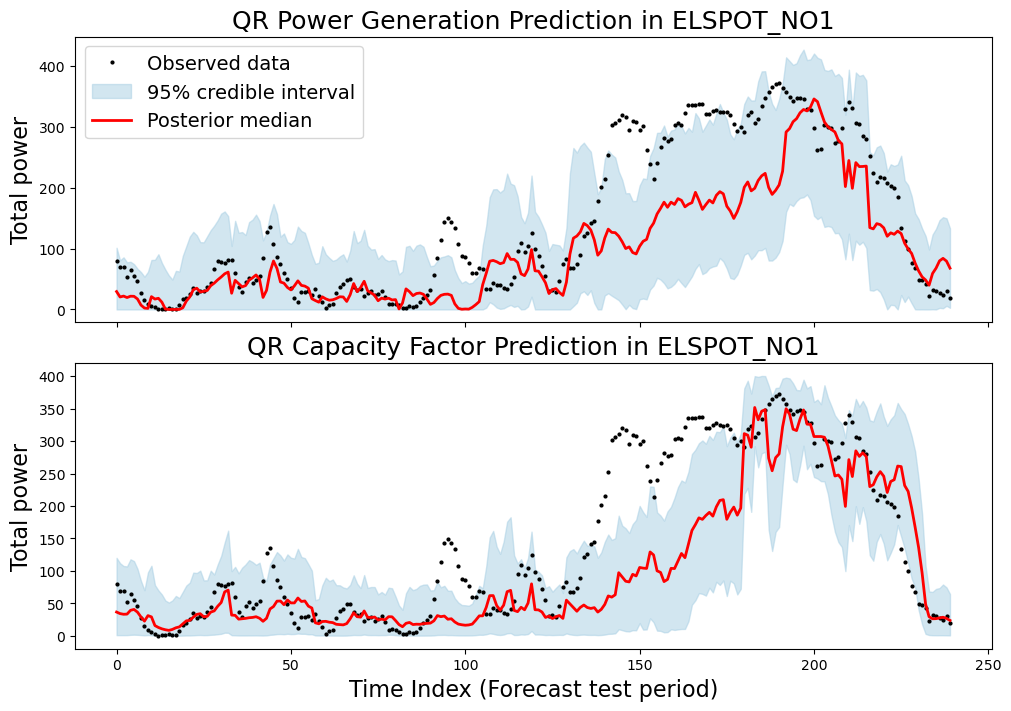

In [73]:
fig, axes = plt.subplots(nrows=2, figsize=(10, 7), sharex=True, constrained_layout=True)

ax = axes[0]
ax.plot(
    eval_data["Y_eval_gen"],
    ".",
    color="black",
    label="Observed data",
    markersize=4,
)

# file_name = "WindPowerQuantile_2025-12-02_11-34-46_fore_ELSPOT_NO1"
# file_name="WindPowerModel_simple_2025-12-02_11-11-30_fore_ELSPOT_NO1"
# file_name = "WindPowerQuantile_2025-12-03_14-57-43_now_gen_ELSPOT_NO1"
file_name = "WindPowerQuantile_2025-12-04_12-21-40_now_gen_ELSPOT_NO1"
# file_name = "WindPowerQuantile_2025-12-03_14-54-34_now_cf_ELSPOT_NO1"
# file_name = "WindPowerModel_simple_2025-12-01_10-31-55_ELSPOT_NO1"

forecast, forecast_extended = evaluate_QR(file_name)

ax.fill_between(
    np.arange(24 * len(evaluation_dates)),
    forecast_extended[i]["hdi_lower"].values,
    forecast_extended[i]["hdi_upper"].values,
    color="#A6CEE3",
    alpha=0.5,
    label="95% credible interval",
)

ax.plot(
    forecast_extended[i]["median"].values, color="red", label="Posterior median", lw=2
)

ax.set(
    ylabel="Total power",
    title=f"QR Power Generation Prediction in {bid_zone}",
)
ax.legend(fontsize=14)
ax.title.set_fontsize(18)
ax.xaxis.label.set_size(16)
ax.yaxis.label.set_size(16)


ax = axes[1]
ax.plot(
    eval_data["Y_eval_gen"],
    ".",
    color="black",
    label="Observed data",
    markersize=4,
)
# file_name = "WindPowerQuantile_2025-12-02_11-34-46_fore_ELSPOT_NO1"
# file_name="WindPowerModel_simple_2025-12-02_11-11-30_fore_ELSPOT_NO1"
# file_name = "WindPowerQuantile_2025-12-03_14-57-43_now_gen_ELSPOT_NO1"
file_name = "WindPowerQuantile_2025-12-03_14-54-34_now_cf_ELSPOT_NO1"
# file_name = "WindPowerModel_simple_2025-12-01_10-31-55_ELSPOT_NO1"

forecast, forecast_extended = evaluate_QR(file_name)

ax.fill_between(
    np.arange(24 * len(evaluation_dates)),
    forecast_extended[i]["hdi_lower"].values,
    forecast_extended[i]["hdi_upper"].values,
    color="#A6CEE3",
    alpha=0.5,
    label="95% credible interval",
)

ax.plot(
    forecast_extended[i]["median"].values, color="red", label="Posterior median", lw=2
)

ax.set(
    xlabel="Time Index (Forecast test period)",
    ylabel="Total power",
    title=f"QR Capacity Factor Prediction in {bid_zone}",
)
ax.title.set_fontsize(18)
ax.xaxis.label.set_size(16)
ax.yaxis.label.set_size(16)

plt.show()

model_mw_gamma
Loading specified checkpoint: ../checkpoints/model_mw_gamma_2025-11-21_10-30-46_gen_ELSPOT_NO1.pkl
model_cf_beta
Loading specified checkpoint: ../checkpoints/model_cf_beta_2025-12-01_10-03-45_cf_ELSPOT_NO1.pkl


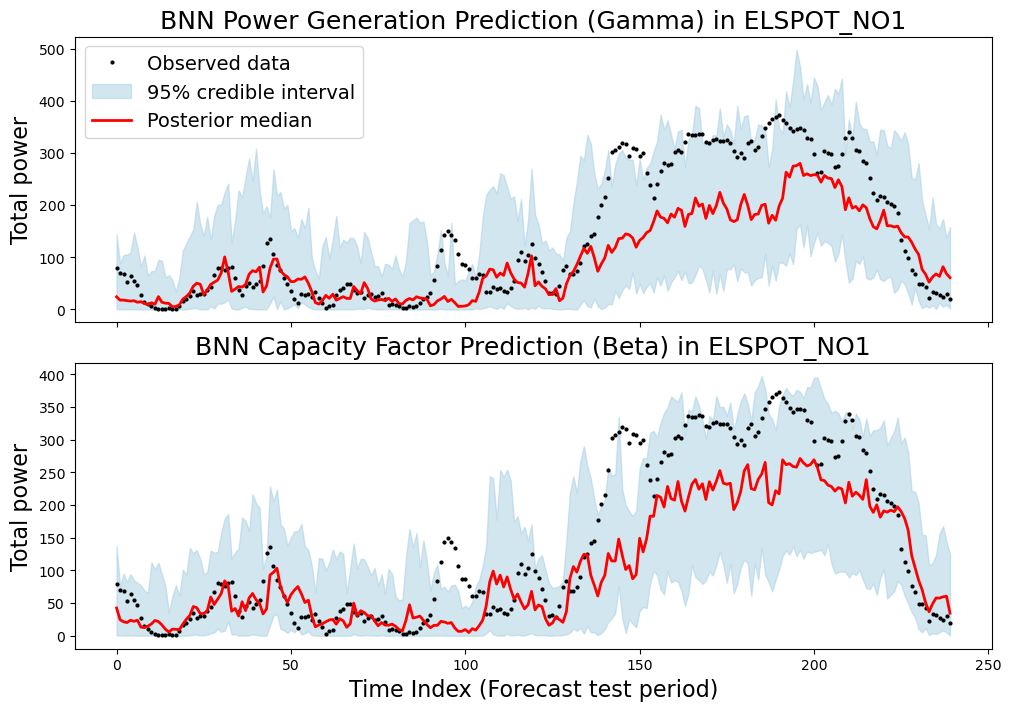

In [ ]:
fig, axes = plt.subplots(nrows=2, figsize=(10, 7), sharex=True, constrained_layout=True)

ax = axes[0]
ax.plot(
    eval_data["Y_eval_gen"],
    ".",
    color="black",
    label="Observed data",
    markersize=4,
)

file_name = "model_mw_gamma_2025-11-21_10-30-46_gen_ELSPOT_NO1"
forecast, forecast_extended = evaluate_BNN(file_name)

ax.fill_between(
    np.arange(24 * len(evaluation_dates)),
    forecast_extended[i]["hdi_lower"].values,
    forecast_extended[i]["hdi_upper"].values,
    color="#A6CEE3",
    alpha=0.5,
    label="95% credible interval",
)

ax.plot(
    forecast_extended[i]["median"].values, color="red", label="Posterior median", lw=2
)

ax.set(
    ylabel="Total power",
    title=f"BNN Power Generation Prediction (Gamma) in {bid_zone}",
)
ax.legend(fontsize=14)
ax.title.set_fontsize(18)
ax.xaxis.label.set_size(16)
ax.yaxis.label.set_size(16)


ax = axes[1]
ax.plot(
    eval_data["Y_eval_gen"],
    ".",
    color="black",
    label="Observed data",
    markersize=4,
)
file_name = "model_cf_beta_2025-12-01_10-03-45_cf_ELSPOT_NO1"

forecast, forecast_extended = evaluate_BNN(file_name)

ax.fill_between(
    np.arange(24 * len(evaluation_dates)),
    forecast_extended[i]["hdi_lower"].values,
    forecast_extended[i]["hdi_upper"].values,
    color="#A6CEE3",
    alpha=0.5,
    label="95% credible interval",
)

ax.plot(
    forecast_extended[i]["median"].values, color="red", label="Posterior median", lw=2
)

ax.set(
    xlabel="Time Index (Forecast test period)",
    ylabel="Total power",
    title=f"BNN Capacity Factor Prediction (Beta) in {bid_zone}",
)
ax.title.set_fontsize(18)
ax.xaxis.label.set_size(16)
ax.yaxis.label.set_size(16)

plt.show()